# 54. M_maha_free vs 현재 최종 모델(통합) — 샷 단위 / 행 단위 지표 비교

| 평가 틀 | 단위 | 비고 |
|---|---|---|
| **행 (공식 2차, LH/RH)** | 캐비티 행 | 대회 공식 형태. CN7 1,211행·불량 17행 →  **AP 0.373**이 이 틀 (같은 샷 LH/RH는 같은 점수) |
| 샷 (2차) | 사출 1회 | LH·RH 중 하나라도 불량이면 불량 샷 |
| 샷 (1차+2차) | 사출 1회 | labeled 전체 |

- 모델: `M_maha_free`(최종 모델 단독) vs `P 통합`(CN7 경보+std4 / RG3 가스 RF+N1, 시간 순·LORO)
- 지표: AP · PR-AUC · ROC-AUC · R-Precision · 무작위 대비·유의 · (행) 상한 F1 / 검사 5·10·15·20%의 TP·FP·FN · Precision · Recall · F1 · 예산 상한 F1 · F1/상한 · 정규화 Precision · 무작위 대비 · 가스/미성형
- 공통 제외: 초기허용불량, RG3 R6 (팀원 표가 R6 포함이면 RG3 숫자는 다를 수 있음)
- 실행 시간: 수 분 (52번과 같은 점수 계산)

In [1]:
import pandas as pd
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40); pd.set_option('display.max_rows', 300)
%load_ext autoreload
%autoreload 2
import metric_compare as MC
R = MC.run(products=('cn7', 'rg3'), seeds=(0,))

[cn7] 샷 (2차) 완료
[cn7] 행 (공식 2차, LH/RH) 완료
[cn7] 샷 (1차+2차) 완료
[rg3] 샷 (2차) 완료
[rg3] 행 (공식 2차, LH/RH) 완료
[rg3] 샷 (1차+2차) 완료


## ① 순위 전체 지표 (검사 비율 무관) — AP · ROC-AUC · R-Precision · 유의

In [2]:
cols = ['제품', '평가 틀', '모델', '평가 대상', '불량', '불량률', 'AP', 'PR-AUC(사다리꼴)', 'ROC-AUC', 'R-Precision', '무작위 AP 평균', 'AP / 무작위', '유의', '상한 F1 (같은 샷 동점)']
display(R['rank'][[c for c in cols if c in R['rank'].columns]].round(3))

,제품,평가 틀,모델,평가 대상,불량,불량률,AP,PR-AUC(사다리꼴),ROC-AUC,R-Precision,무작위 AP 평균,AP / 무작위,유의,상한 F1 (같은 샷 동점)
0,cn7,샷 (2차),M_maha_free (최종 모델 단독),606.0,14.0,0.023,0.247,0.244,0.609,0.214,0.033,7.556,1/1,NaN
1,cn7,샷 (2차),P 통합: 경보 먼저 + std4,606.0,14.0,0.023,0.265,0.262,0.708,0.214,0.033,8.120,1/1,NaN
2,cn7,"행 (공식 2차, LH/RH)",M_maha_free (최종 모델 단독),1211.0,17.0,0.014,0.373,0.372,0.677,0.353,0.019,19.845,1/1,0.756
3,cn7,"행 (공식 2차, LH/RH)",P 통합: 경보 먼저 + std4,1211.0,17.0,0.014,0.384,0.382,0.758,0.353,0.019,20.415,1/1,0.756
4,cn7,샷 (1차+2차),M_maha_free (최종 모델 단독),1974.0,15.0,0.008,0.212,0.211,0.569,0.200,0.011,18.847,1/1,NaN
5,cn7,샷 (1차+2차),P 통합: 경보 먼저 + std4,1974.0,15.0,0.008,0.170,0.194,0.736,0.200,0.011,15.159,1/1,NaN
6,rg3,샷 (2차),M_maha_free (최종 모델 단독),591.0,25.0,0.042,0.048,0.044,0.554,0.040,0.052,0.919,0/1,NaN
7,rg3,샷 (2차),P 통합: 가스 RF(시간 순) + N1,591.0,25.0,0.042,0.150,0.131,0.715,0.240,0.052,2.901,1/1,NaN
8,rg3,샷 (2차),P 통합: 가스 RF(LORO) + N1,591.0,25.0,0.042,0.105,0.094,0.688,0.080,0.052,2.026,1/1,NaN
9,rg3,"행 (공식 2차, LH/RH)",M_maha_free (최종 모델 단독),1182.0,25.0,0.021,0.024,0.022,0.552,0.000,0.027,0.892,0/1,0.667


## ② 검사 비율별 (5·10·15·20%)

In [3]:
for p in ('cn7', 'rg3'):
    for fr in ('행 (공식 2차, LH/RH)', '샷 (2차)', '샷 (1차+2차)'):
        t = R['budget'][(R['budget']['제품'] == p) & (R['budget']['평가 틀'] == fr)]
        print(f'===== {p.upper()} · {fr}')
        display(t.drop(columns=['제품', '평가 틀']).round(3))

===== CN7 · 행 (공식 2차, LH/RH)


,모델,검사 비율,검사 수 K,불량,TP,FP,FN,Precision,Recall,F1,예산 상한 F1,F1 / 예산 상한,정규화 Precision,무작위 대비(배),가스,미성형
8,M_maha_free (최종 모델 단독),5%,61.0,6.0/17,6.0,55.0,11.0,0.098,0.353,0.154,0.436,0.353,0.353,7.007,2.0/13,4.0/4
9,M_maha_free (최종 모델 단독),10%,121.0,8.0/17,8.0,113.0,9.0,0.066,0.471,0.116,0.246,0.471,0.471,4.710,4.0/13,4.0/4
10,M_maha_free (최종 모델 단독),15%,182.0,8.0/17,8.0,174.0,9.0,0.044,0.471,0.080,0.171,0.471,0.471,3.131,4.0/13,4.0/4
11,M_maha_free (최종 모델 단독),20%,242.0,8.0/17,8.0,234.0,9.0,0.033,0.471,0.062,0.131,0.471,0.471,2.355,4.0/13,4.0/4
12,P 통합: 경보 먼저 + std4,5%,61.0,6.0/17,6.0,55.0,11.0,0.098,0.353,0.154,0.436,0.353,0.353,7.007,2.0/13,4.0/4
13,P 통합: 경보 먼저 + std4,10%,121.0,9.0/17,9.0,112.0,8.0,0.074,0.529,0.130,0.246,0.529,0.529,5.298,5.0/13,4.0/4
14,P 통합: 경보 먼저 + std4,15%,182.0,11.0/17,11.0,171.0,6.0,0.060,0.647,0.111,0.171,0.647,0.647,4.305,7.0/13,4.0/4
15,P 통합: 경보 먼저 + std4,20%,242.0,11.0/17,11.0,231.0,6.0,0.045,0.647,0.085,0.131,0.647,0.647,3.238,7.0/13,4.0/4


===== CN7 · 샷 (2차)


,모델,검사 비율,검사 수 K,불량,TP,FP,FN,Precision,Recall,F1,예산 상한 F1,F1 / 예산 상한,정규화 Precision,무작위 대비(배),가스,미성형
0,M_maha_free (최종 모델 단독),5%,30.0,3.0/14,3.0,27.0,11.0,0.100,0.214,0.136,0.636,0.214,0.214,4.329,2.0/13,3.0/3
1,M_maha_free (최종 모델 단독),10%,61.0,5.0/14,5.0,56.0,9.0,0.082,0.357,0.133,0.373,0.357,0.357,3.548,4.0/13,3.0/3
2,M_maha_free (최종 모델 단독),15%,91.0,5.0/14,5.0,86.0,9.0,0.055,0.357,0.095,0.267,0.357,0.357,2.378,4.0/13,3.0/3
3,M_maha_free (최종 모델 단독),20%,121.0,5.0/14,5.0,116.0,9.0,0.041,0.357,0.074,0.207,0.357,0.357,1.789,4.0/13,3.0/3
4,P 통합: 경보 먼저 + std4,5%,30.0,3.0/14,3.0,27.0,11.0,0.100,0.214,0.136,0.636,0.214,0.214,4.329,2.0/13,3.0/3
5,P 통합: 경보 먼저 + std4,10%,61.0,6.0/14,6.0,55.0,8.0,0.098,0.429,0.160,0.373,0.429,0.429,4.258,5.0/13,3.0/3
6,P 통합: 경보 먼저 + std4,15%,91.0,8.0/14,8.0,83.0,6.0,0.088,0.571,0.152,0.267,0.571,0.571,3.805,7.0/13,3.0/3
7,P 통합: 경보 먼저 + std4,20%,121.0,8.0/14,8.0,113.0,6.0,0.066,0.571,0.119,0.207,0.571,0.571,2.862,7.0/13,3.0/3


===== CN7 · 샷 (1차+2차)


...

,모델,검사 비율,검사 수 K,불량,TP,FP,FN,Precision,Recall,F1,예산 상한 F1,F1 / 예산 상한,정규화 Precision,무작위 대비(배),가스,미성형
36,M_maha_free (최종 모델 단독),5%,59.0,1.0/25,1.0,58.0,24.0,0.017,0.04,0.024,0.595,0.04,0.04,0.801,1.0/17,0.0/8
37,M_maha_free (최종 모델 단독),10%,118.0,2.0/25,2.0,116.0,23.0,0.017,0.08,0.028,0.350,0.08,0.08,0.801,1.0/17,1.0/8
38,M_maha_free (최종 모델 단독),15%,177.0,3.0/25,3.0,174.0,22.0,0.017,0.12,0.030,0.248,0.12,0.12,0.801,2.0/17,1.0/8
39,M_maha_free (최종 모델 단독),20%,236.0,4.0/25,4.0,232.0,21.0,0.017,0.16,0.031,0.192,0.16,0.16,0.801,2.0/17,2.0/8
40,P 통합: 가스 RF(시간 순) + N1,5%,59.0,6.0/25,6.0,53.0,19.0,0.102,0.24,0.143,0.595,0.24,0.24,4.808,3.0/17,3.0/8
41,P 통합: 가스 RF(시간 순) + N1,10%,118.0,10.0/25,10.0,108.0,15.0,0.085,0.40,0.140,0.350,0.40,0.40,4.007,6.0/17,4.0/8
42,P 통합: 가스 RF(시간 순) + N1,15%,177.0,10.0/25,10.0,167.0,15.0,0.056,0.40,0.099,0.248,0.40,0.40,2.671,6.0/17,4.0/8
43,P 통합: 가스 RF(시간 순) + N1,20%,236.0,11.0/25,11.0,225.0,14.0,0.047,0.44,0.084,0.192,0.44,0.44,2.204,7.0/17,4.0/8
44,P 통합: 가스 RF(LORO) + N1,5%,59.0,2.0/25,2.0,57.0,23.0,0.034,0.08,0.048,0.595,0.08,0.08,1.603,1.0/17,1.0/8
45,P 통합: 가스 RF(LORO) + N1,10%,118.0,9.0/25,9.0,109.0,16.0,0.076,0.36,0.126,0.350,0.36,0.36,3.606,6.0/17,3.0/8


===== RG3 · 샷 (2차)


,모델,검사 비율,검사 수 K,불량,TP,FP,FN,Precision,Recall,F1,예산 상한 F1,F1 / 예산 상한,정규화 Precision,무작위 대비(배),가스,미성형
24,M_maha_free (최종 모델 단독),5%,30.0,1.0/25,1.0,29.0,24.0,0.033,0.04,0.036,0.909,0.04,0.04,0.788,1.0/17,0.0/8
25,M_maha_free (최종 모델 단독),10%,59.0,2.0/25,2.0,57.0,23.0,0.034,0.08,0.048,0.595,0.08,0.08,0.801,1.0/17,1.0/8
26,M_maha_free (최종 모델 단독),15%,89.0,3.0/25,3.0,86.0,22.0,0.034,0.12,0.053,0.439,0.12,0.12,0.797,2.0/17,1.0/8
27,M_maha_free (최종 모델 단독),20%,118.0,4.0/25,4.0,114.0,21.0,0.034,0.16,0.056,0.350,0.16,0.16,0.801,2.0/17,2.0/8
28,P 통합: 가스 RF(시간 순) + N1,5%,30.0,7.0/25,7.0,23.0,18.0,0.233,0.28,0.255,0.909,0.28,0.28,5.516,4.0/17,3.0/8
29,P 통합: 가스 RF(시간 순) + N1,10%,59.0,10.0/25,10.0,49.0,15.0,0.169,0.40,0.238,0.595,0.40,0.40,4.007,6.0/17,4.0/8
30,P 통합: 가스 RF(시간 순) + N1,15%,89.0,10.0/25,10.0,79.0,15.0,0.112,0.40,0.175,0.439,0.40,0.40,2.656,6.0/17,4.0/8
31,P 통합: 가스 RF(시간 순) + N1,20%,118.0,11.0/25,11.0,107.0,14.0,0.093,0.44,0.154,0.350,0.44,0.44,2.204,7.0/17,4.0/8
32,P 통합: 가스 RF(LORO) + N1,5%,30.0,2.0/25,2.0,28.0,23.0,0.067,0.08,0.073,0.909,0.08,0.08,1.576,1.0/17,1.0/8
33,P 통합: 가스 RF(LORO) + N1,10%,59.0,9.0/25,9.0,50.0,16.0,0.153,0.36,0.214,0.595,0.36,0.36,3.606,6.0/17,3.0/8


===== RG3 · 샷 (1차+2차)


,모델,검사 비율,검사 수 K,불량,TP,FP,FN,Precision,Recall,F1,예산 상한 F1,F1 / 예산 상한,정규화 Precision,무작위 대비(배),가스,미성형
48,M_maha_free (최종 모델 단독),5%,30.0,1.0/25,1.0,29.0,24.0,0.033,0.04,0.036,0.909,0.04,0.04,0.788,1.0/17,0.0/8
49,M_maha_free (최종 모델 단독),10%,59.0,2.0/25,2.0,57.0,23.0,0.034,0.08,0.048,0.595,0.08,0.08,0.801,1.0/17,1.0/8
50,M_maha_free (최종 모델 단독),15%,89.0,3.0/25,3.0,86.0,22.0,0.034,0.12,0.053,0.439,0.12,0.12,0.797,2.0/17,1.0/8
51,M_maha_free (최종 모델 단독),20%,118.0,4.0/25,4.0,114.0,21.0,0.034,0.16,0.056,0.350,0.16,0.16,0.801,2.0/17,2.0/8
52,P 통합: 가스 RF(시간 순) + N1,5%,30.0,7.0/25,7.0,23.0,18.0,0.233,0.28,0.255,0.909,0.28,0.28,5.516,4.0/17,3.0/8
53,P 통합: 가스 RF(시간 순) + N1,10%,59.0,10.0/25,10.0,49.0,15.0,0.169,0.40,0.238,0.595,0.40,0.40,4.007,6.0/17,4.0/8
54,P 통합: 가스 RF(시간 순) + N1,15%,89.0,10.0/25,10.0,79.0,15.0,0.112,0.40,0.175,0.439,0.40,0.40,2.656,6.0/17,4.0/8
55,P 통합: 가스 RF(시간 순) + N1,20%,118.0,11.0/25,11.0,107.0,14.0,0.093,0.44,0.154,0.350,0.44,0.44,2.204,7.0/17,4.0/8
56,P 통합: 가스 RF(LORO) + N1,5%,30.0,2.0/25,2.0,28.0,23.0,0.067,0.08,0.073,0.909,0.08,0.08,1.576,1.0/17,1.0/8
57,P 통합: 가스 RF(LORO) + N1,10%,59.0,9.0/25,9.0,50.0,16.0,0.153,0.36,0.214,0.595,0.36,0.36,3.606,6.0/17,3.0/8


## ③ M_maha_free → 통합 모델 비교 (같은 평가 틀·같은 검사 비율)

In [4]:
display(R['compare'])

,제품,평가 틀,검사 비율,통합 모델,AP (maha → 통합),ROC-AUC (maha → 통합),불량 (maha → 통합),Precision (maha → 통합),Recall (maha → 통합),F1 (maha → 통합),ΔTP,가스 (maha → 통합),미성형 (maha → 통합)
0,cn7,샷 (2차),5%,P 통합: 경보 먼저 + std4,0.247 → 0.265,0.609 → 0.708,3.0/14 → 3.0/14,0.100 → 0.100,0.214 → 0.214,0.136 → 0.136,0.0,2.0/13 → 2.0/13,3.0/3 → 3.0/3
1,cn7,샷 (2차),10%,P 통합: 경보 먼저 + std4,0.247 → 0.265,0.609 → 0.708,5.0/14 → 6.0/14,0.082 → 0.098,0.357 → 0.429,0.133 → 0.160,1.0,4.0/13 → 5.0/13,3.0/3 → 3.0/3
2,cn7,샷 (2차),15%,P 통합: 경보 먼저 + std4,0.247 → 0.265,0.609 → 0.708,5.0/14 → 8.0/14,0.055 → 0.088,0.357 → 0.571,0.095 → 0.152,3.0,4.0/13 → 7.0/13,3.0/3 → 3.0/3
3,cn7,샷 (2차),20%,P 통합: 경보 먼저 + std4,0.247 → 0.265,0.609 → 0.708,5.0/14 → 8.0/14,0.041 → 0.066,0.357 → 0.571,0.074 → 0.119,3.0,4.0/13 → 7.0/13,3.0/3 → 3.0/3
4,cn7,"행 (공식 2차, LH/RH)",5%,P 통합: 경보 먼저 + std4,0.373 → 0.384,0.677 → 0.758,6.0/17 → 6.0/17,0.098 → 0.098,0.353 → 0.353,0.154 → 0.154,0.0,2.0/13 → 2.0/13,4.0/4 → 4.0/4
5,cn7,"행 (공식 2차, LH/RH)",10%,P 통합: 경보 먼저 + std4,0.373 → 0.384,0.677 → 0.758,8.0/17 → 9.0/17,0.066 → 0.074,0.471 → 0.529,0.116 → 0.130,1.0,4.0/13 → 5.0/13,4.0/4 → 4.0/4
6,cn7,"행 (공식 2차, LH/RH)",15%,P 통합: 경보 먼저 + std4,0.373 → 0.384,0.677 → 0.758,8.0/17 → 11.0/17,0.044 → 0.060,0.471 → 0.647,0.080 → 0.111,3.0,4.0/13 → 7.0/13,4.0/4 → 4.0/4
7,cn7,"행 (공식 2차, LH/RH)",20%,P 통합: 경보 먼저 + std4,0.373 → 0.384,0.677 → 0.758,8.0/17 → 11.0/17,0.033 → 0.045,0.471 → 0.647,0.062 → 0.085,3.0,4.0/13 → 7.0/13,4.0/4 → 4.0/4
8,cn7,샷 (1차+2차),5%,P 통합: 경보 먼저 + std4,0.212 → 0.170,0.569 → 0.736,4.0/15 → 4.0/15,0.040 → 0.040,0.267 → 0.267,0.070 → 0.070,0.0,3.0/13 → 3.0/13,3.0/4 → 3.0/4
9,cn7,샷 (1차+2차),10%,P 통합: 경보 먼저 + std4,0.212 → 0.170,0.569 → 0.736,5.0/15 → 8.0/15,0.025 → 0.041,0.333 → 0.533,0.047 → 0.075,3.0,4.0/13 → 7.0/13,3.0/4 → 3.0/4


## ④ 그래프 — 검사 비율 vs Recall / F1 (점선 = M_maha_free)

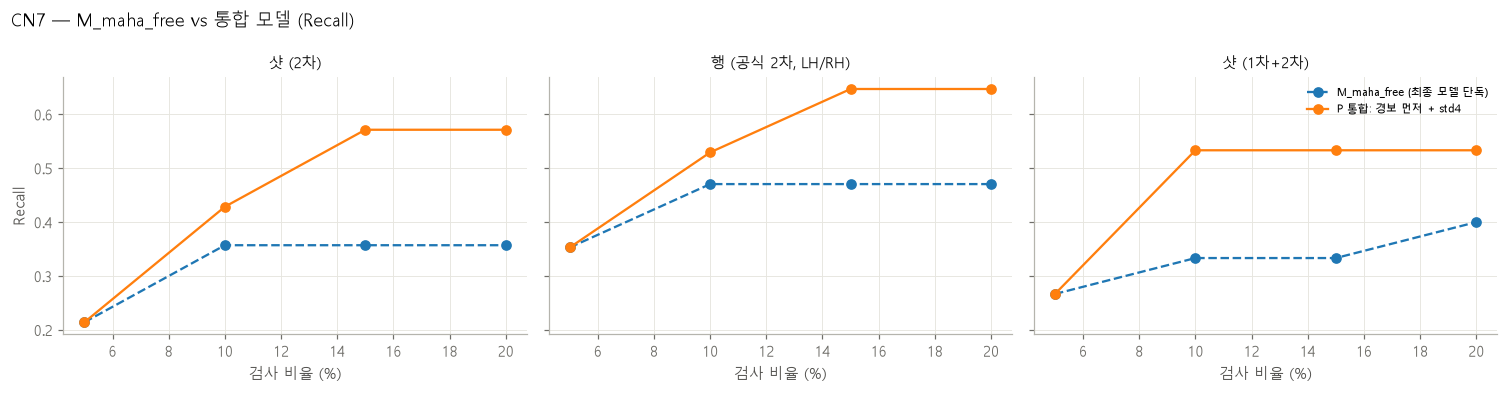

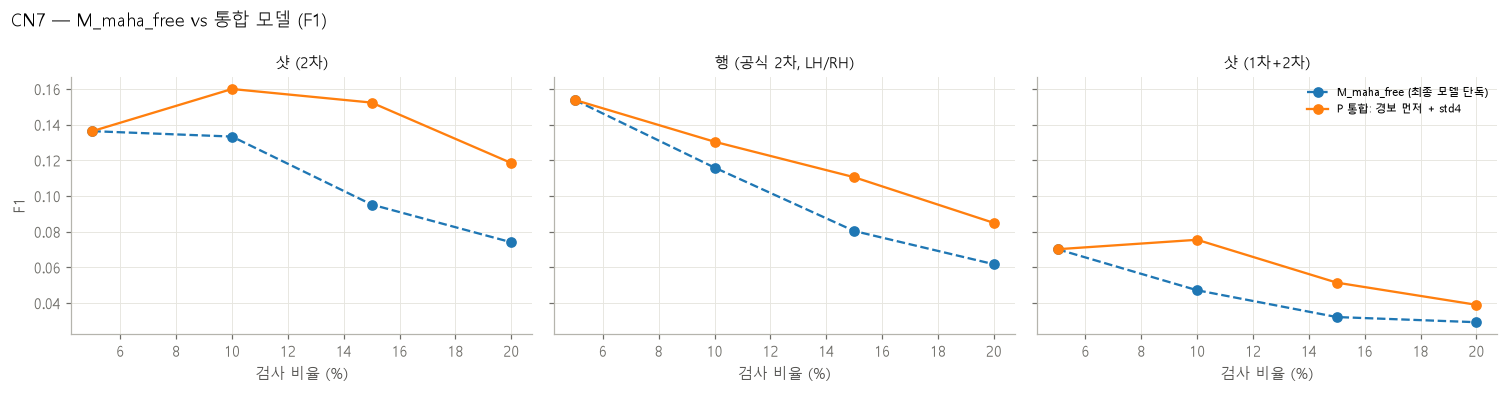

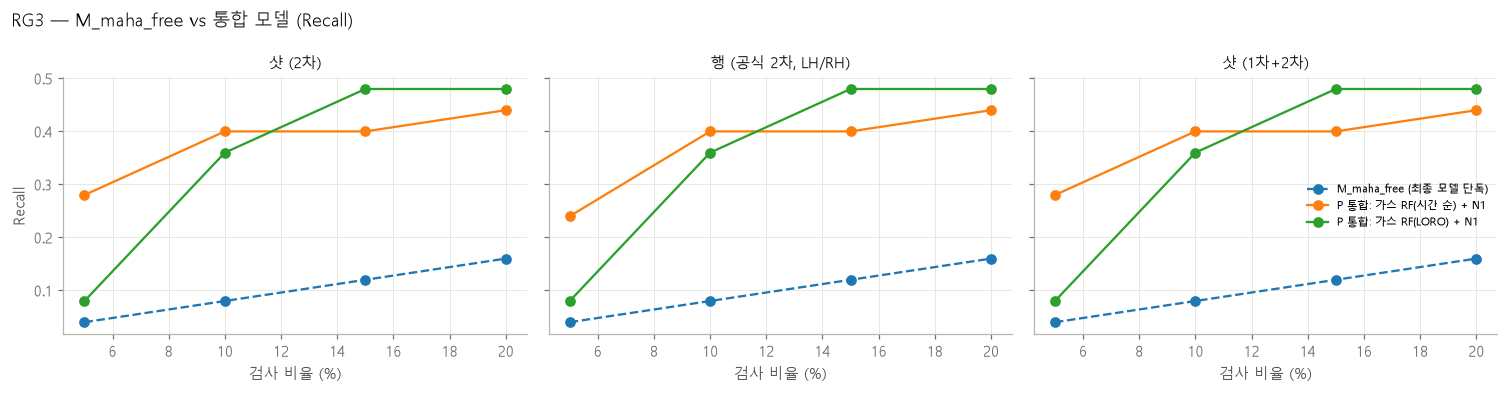

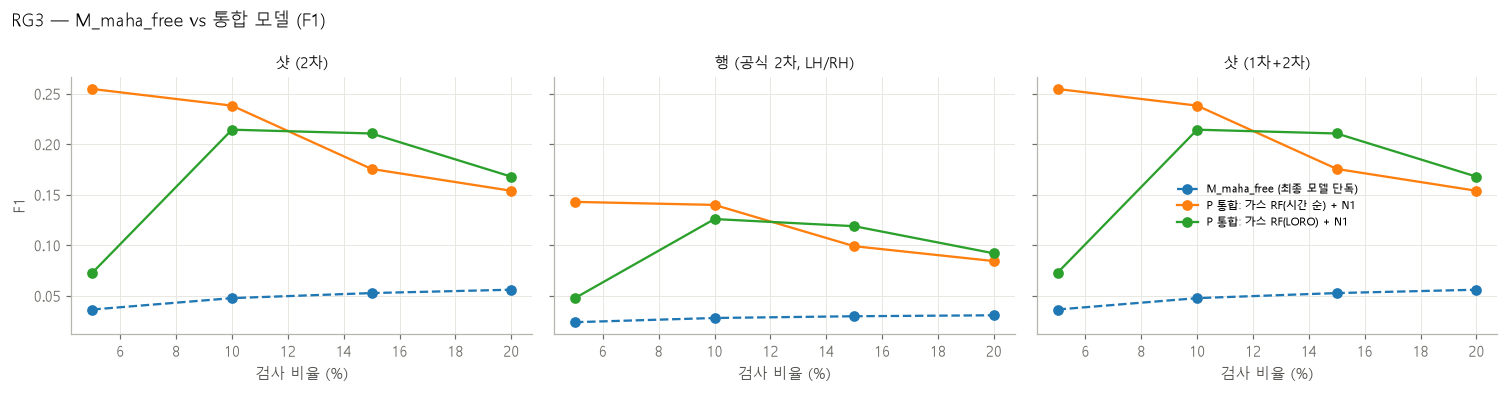

In [5]:
for p in ('cn7', 'rg3'):
    MC.plot(R, p, 'Recall')
    MC.plot(R, p, 'F1')

## 읽는 법
1. **AP 0.373 재현 확인**: CN7 · 행 (공식 2차) · M_maha_free의 AP가 0.373이면 팀원 표와 같은 틀
2. 행 vs 샷: 행은 LH/RH가 같은 점수라 한쪽만 불량인 샷에서 FP가 생김 → **상한 F1**이 1보다 작음. 샷 단위가 현장 검사 단위(사출 1회)에 가까움
3. AP는 순위 맨 위 몇 개에 크게 좌우됨 → CN7은 미성형 3샷이 1~3위라 M_maha_free의 AP가 높게 나옴. 통합 모델은 상위권에 std4 샷이 섞여 **AP는 비슷하거나 낮을 수 있지만, 검사 10~20%의 Recall(불량 포착)은 더 높음** → 검사 우선순위 목적에는 검사 비율별 지표가 더 맞음
4. RG3는 M_maha_free가 무작위 수준 → 통합 모델이 모든 지표에서 높아야 정상
5. 보고서: '행(공식)' 표를 대회 기준 대표로, '샷' 표를 현장 운영 기준으로 같이 제시